# 1 — Path Planning: 3D A\* Search + Adaptive B-Spline Smoothing

**Paper reference:** Nikolaiev & Novotarskyi, *"An Enhanced Adaptive B-spline Smoothing Approach for UAV Path Planning,"* IJISA, Vol. 17, No. 4, 2025 (`bspline1.pdf`).

This notebook walks the **path-planning half** of the project end to end, pairing each stage's math from the paper with the actual repository code that implements it (nothing here is reimplemented — every cell imports and runs the real modules in `path_planning/`, `environment/`).

**Pipeline covered in this notebook:**

```
3D Environment  →  3D A* Search  →  Waypoint Reduction  →  Adaptive B-Spline Smoothing
 (obstacles)        (26-conn.)        (min-distance)         Stage 1: init (least-squares)
                                                               Stage 2: GA knot optimization
                                                               Stage 3: curvature refinement
```

The attitude-control half (Paper 2) is covered in `02_quaternion_attitude_control_theory.ipynb`, and the two are merged end-to-end in `03_full_pipeline_merged_simulation.ipynb`.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# Make the repo root importable (this notebook lives in notebooks/)
REPO_ROOT = os.path.abspath('..')
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

from environment.obstacles import Environment3D, Obstacle3D
from path_planning.astar import AStarPlanner3D
from path_planning.bspline import BSplinePath
from path_planning.knot_ga import KnotGA
from path_planning.curvature_refine import CurvatureRefiner
from path_planning.path_smoother import AdaptiveBSplineSmoother

np.random.seed(7)
plt.rcParams['figure.dpi'] = 100
print("Modules loaded from:", REPO_ROOT)

Modules loaded from: c:\Users\prajw\OneDrive - Amrita Vishwa Vidyapeetham\Desktop\SEM5\Drones\Drones_S5_CD8_Adaptive_BSpline_Smoothing_and_Altitude_Control


## 1.1 The 3D Obstacle Environment

The paper's simulation airspace is a $2000\times2000\times500$ m volume; the UAV must fly from
$\mathbf{p}_{start}=(0,0,20)$ to $\mathbf{p}_{goal}=(2000,1800,200)$, around cylindrical (towers) and
cuboidal (buildings) obstacles, each inflated by a safety buffer $b$ (paper default $b=5$ m).

A point $\mathbf{p}$ collides with an obstacle if it falls inside the buffered volume — this is exactly
`Environment3D` / `Obstacle3D` in `environment/obstacles.py`.

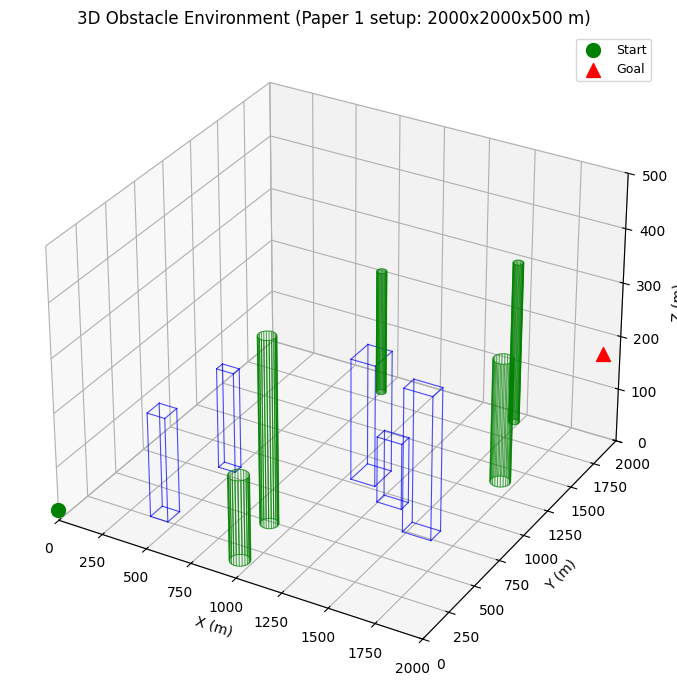

Obstacles placed: 10 (5 cylinders, 5 cuboids)


In [2]:
env = Environment3D()
env.add_random_obstacles(n_cylinders=5, n_cuboids=5, seed=42, buffer=5.0)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')
env.visualize(ax)
ax.set_title("3D Obstacle Environment (Paper 1 setup: 2000x2000x500 m)")
plt.tight_layout()
plt.show()

print(f"Obstacles placed: {len(env.obstacles)} "
      f"({sum(o.shape=='cylinder' for o in env.obstacles)} cylinders, "
      f"{sum(o.shape=='cuboid' for o in env.obstacles)} cuboids)")

## 1.2 3D A\* Search

On a 26-connected voxel grid of resolution $r$:

$$f(n) = g(n) + h(n)$$
$$g(n) = g(\mathrm{parent}) + \lVert \Delta \rVert \cdot r, \qquad \Delta \in \{-1,0,1\}^3 \setminus \{0\}$$
$$h(n) = \big\lVert (n - n_{goal})\cdot r \big\rVert_2 \quad\text{(Euclidean — admissible on a 3D grid)}$$

`AStarPlanner3D.plan()` implements this with a binary-heap open set; cells inside an obstacle's buffered
volume are rejected during expansion. The raw voxel path is then reduced to a sparse set of waypoints
(`smooth_waypoints`, a minimum-distance filter) before it's handed to the B-Spline smoother — spline fitting
needs a short, well-spaced waypoint list, not every visited grid cell.

Raw A* path:        40 grid cells
Reduced waypoints:  15 points
Path length (raw):  2797.8 m


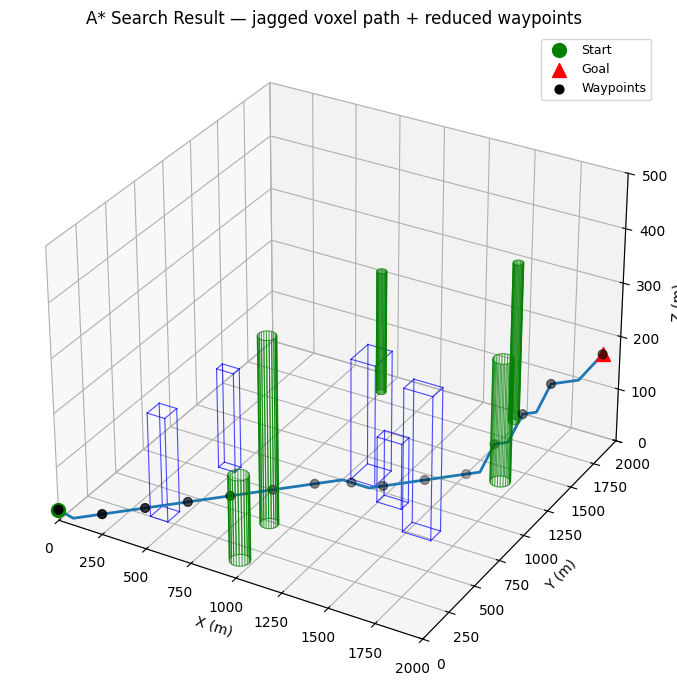

In [3]:
planner = AStarPlanner3D(env, grid_resolution=50)
raw_path = planner.plan(env.start, env.goal)
waypoints_astar = planner.smooth_waypoints(raw_path, min_distance=150)
waypoints_astar = np.array(waypoints_astar)

print(f"Raw A* path:        {len(raw_path)} grid cells")
print(f"Reduced waypoints:  {len(waypoints_astar)} points")
print(f"Path length (raw):  {planner.compute_path_length(raw_path):.1f} m")

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')
env.visualize(ax, waypoints=waypoints_astar, paths=[np.array(raw_path)])
ax.set_title("A* Search Result — jagged voxel path + reduced waypoints")
plt.tight_layout()
plt.show()

## 1.3 B-Spline Curve Representation (Eq. 1)

Each coordinate of the trajectory is a linear combination of control points $\mathbf{Q}_i \in \mathbb{R}^d$
and degree-$p$ B-Spline basis functions:

$$C(u) = \sum_{i=0}^{n} N_{i,p}(u)\, \mathbf{Q}_i, \qquad u \in [u_p, u_{n+1}]$$

with knot vector $U=\{u_0,\dots,u_{n+p+1}\}$. For UAV smoothing the cubic case ($p=3$) is used throughout —
it gives $C^2$ continuity (smooth acceleration) with a low polynomial degree.

**Basis functions — Cox–de Boor recursion:**

$$N_{i,0}(u) = \begin{cases}1 & u_i \le u < u_{i+1}\\ 0 & \text{otherwise}\end{cases}$$
$$N_{i,p}(u) = \frac{u-u_i}{u_{i+p}-u_i}N_{i,p-1}(u) + \frac{u_{i+p+1}-u}{u_{i+p+1}-u_{i+1}}N_{i+1,p-1}(u)$$

**Parameterization** (mapping waypoints $P_k$ to $u_k \in [0,1]$) — chord length, the repo's default:

$$u_0=0,\qquad u_i = u_{i-1}+\frac{\lVert P_i-P_{i-1}\rVert}{\sum_k \lVert P_k-P_{k-1}\rVert},\qquad u_n=1$$

**Control-point solve** — the interpolation system $\mathbf N\mathbf Q=\mathbf P$ built from $N_{j,p}(u_k)$ is
solved as least-squares normal equations (`np.linalg.lstsq` on $\mathbf N^\top\mathbf N$), which degrades
gracefully instead of failing on a near-singular basis matrix. All of this is `BSplinePath` in
`path_planning/bspline.py` — a hand-written, pure-NumPy recursive Cox–de Boor implementation.

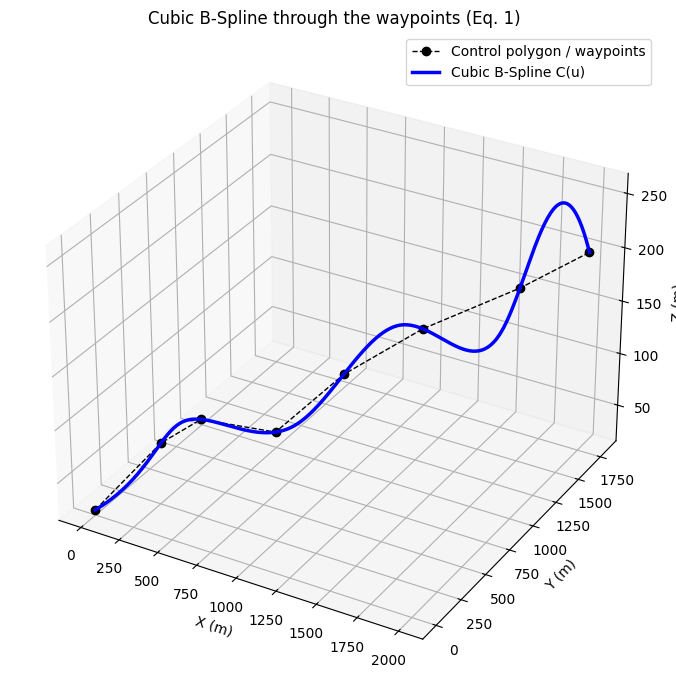

Degree:            3
Knot vector:       [0.  0.  0.  0.  0.2 0.4 0.6 0.8 1.  1.  1.  1. ]
Path length:       3065.4 m


In [4]:
# Use the project's canonical 8-waypoint demo set (same as main.py) — a clean,
# hand-picked case that makes the GA/refinement stages easy to see.
waypoints = np.array([
    [0,    0,    20],
    [300,  200,  80],
    [600,  150,  120],
    [900,  400,  100],
    [1200, 600,  150],
    [1500, 900,  180],
    [1800, 1400, 190],
    [2000, 1800, 200]
], dtype=float)

spline_demo = BSplinePath(waypoints)   # degree 3, chord-length params, uniform interior knots
pts = spline_demo.sample_path(300)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot(waypoints[:,0], waypoints[:,1], waypoints[:,2], 'ko--', lw=1, ms=6, label='Control polygon / waypoints')
ax.plot(pts[:,0], pts[:,1], pts[:,2], 'b-', lw=2.5, label='Cubic B-Spline C(u)')
ax.set_title("Cubic B-Spline through the waypoints (Eq. 1)")
ax.set_xlabel('X (m)'); ax.set_ylabel('Y (m)'); ax.set_zlabel('Z (m)')
ax.legend()
plt.tight_layout()
plt.show()

print(f"Degree:            {spline_demo.degree}")
print(f"Knot vector:       {np.round(spline_demo.knot_vector, 3)}")
print(f"Path length:       {spline_demo.path_length():.1f} m")

## 1.4 Curvature (Eq. 2)

$$\kappa(u) = \frac{\lVert C'(u)\times C''(u)\rVert}{\lVert C'(u)\rVert^3}$$

The flight-dynamics constraint from the paper (§2.3, Eq. 3) requires $\kappa(u) \le \kappa_{max}$ (and
similarly for velocity/acceleration) everywhere along the path — turns tighter than the airframe can bank
into are physically infeasible.

`BSplinePath.evaluate_derivative` gets $C'(u)$, $C''(u)$ via central finite differences ($h=10^{-5}$);
`compute_curvature` then evaluates Eq. 2 directly.

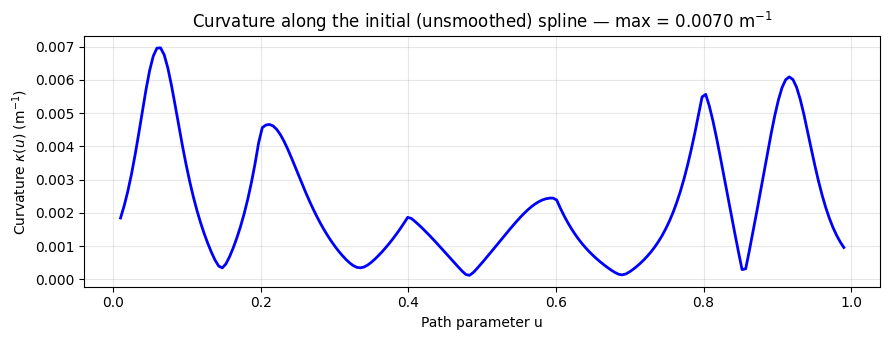

In [5]:
params = np.linspace(0.01, 0.99, 200)
curv = [spline_demo.compute_curvature(u) for u in params]

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(params, curv, 'b-', lw=2)
ax.set_xlabel('Path parameter u'); ax.set_ylabel(r'Curvature $\kappa(u)$ (m$^{-1}$)')
ax.set_title(f'Curvature along the initial (unsmoothed) spline — max = {max(curv):.4f} m$^{{-1}}$')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 1.5 Objective Function (Eq. 4) — Paper's Full 5-Term Formulation

$$F(U, D) = w_1 F_{data}(U,D) + w_2 F_{curv}(U,D) + w_3 F_{dyn}(U,D) + w_4 F_{len}(U,D) + w_5 F_{knot}(U)$$

| Term | Meaning |
|---|---|
| $F_{data}$ | data fidelity — squared distance between the spline and the raw waypoints |
| $F_{curv}$ | curvature penalty — penalizes $\kappa(u)$ exceeding $\kappa_{max}$ |
| $F_{dyn}$ | dynamic feasibility — penalizes violating velocity/acceleration bounds |
| $F_{len}$ | path length — total arc length of $C(u)$ |
| $F_{knot}$ | knot regularization — discourages clustered/uneven knot spacing |

**This codebase's `KnotGA` implements 4 of the 5 terms** — $F_{dyn}$ (the velocity/acceleration penalty) is
not implemented (confirmed by grep — no velocity/acceleration constraint exists anywhere in the codebase).
The implemented cost, minimized by the GA (`path_planning/knot_ga.py`):

$$\text{cost}(U) = w_1\,\text{MSE}(U) + w_2\sum_{u}\max(0,\ \kappa(u)-\kappa_{max})^2 + w_3\,L(U) + w_4\sum_i(\Delta u_i - \overline{\Delta u})^2$$

with default weights $w_1=1.0,\ w_2=2.0,\ w_3=1.0,\ w_4=0.5$. Only the **interior** knots
$\{u_{p+1},\dots,u_{n+p}\}$ are chromosome genes (searched over a fixed range $[0.01, 0.99]$, then sorted);
the $p{+}1$-fold repeated endpoints stay fixed to anchor the domain.

In [6]:
import inspect
print(inspect.getsource(KnotGA.evaluate_chromosome))

    def evaluate_chromosome(self, inner_knots):
        from .bspline import BSplinePath

        knots = self.build_knot_vector(inner_knots)

        try:
            spline = BSplinePath(self.waypoints, knots)
        except:
            return 1e6   # invalid chromosome

        # Term 1 — Data fidelity (mean squared error, not summed —
        # a raw sum scales with n_waypoints and, at this environment's
        # scale, drowns out the curvature penalty term below by
        # several orders of magnitude, making the GA blind to curvature)
        fidelity = 0
        for i, wp in enumerate(self.waypoints):
            u = spline.params[i]
            pt = spline.evaluate(u)
            fidelity += np.linalg.norm(wp - pt)**2
        fidelity /= len(self.waypoints)

        # Term 2 — Curvature penalty
        params = np.linspace(0.01, 0.99, 50)
        curvatures = [spline.compute_curvature(u) for u in params]
        curv_penalty = sum(max(0, k - self.kappa_max)**2
              

## 1.6 Stage 2 — Global Optimization via Genetic Algorithm

The GA (`pygad`, wrapped by `KnotGA`) searches only the interior knot vector. Each generation:
**selection** (low-cost chromosomes preferred) → **crossover** (single-point) → **mutation** (random,
20% of genes) — exactly as described in the paper §3.2.

In [7]:
ga = KnotGA(waypoints, n_inner_knots=6, n_generations=25, population_size=20, kappa_max=0.5)
best_knots = ga.run()
spline_ga = BSplinePath(waypoints, best_knots)

print(f"\nBaseline (Stage 1):  length={spline_demo.path_length():.1f}m, max_kappa={spline_demo.max_curvature():.4f}")
print(f"GA-optimized (Stage 2): length={spline_ga.path_length():.1f}m, max_kappa={spline_ga.max_curvature():.4f}")

Running Genetic Algorithm for knot optimization...
GA complete. Best cost: 2899.7654

Baseline (Stage 1):  length=3065.4m, max_kappa=0.0070
GA-optimized (Stage 2): length=2899.8m, max_kappa=0.0141


## 1.7 Stage 3 — Curvature-Aware Control-Point Refinement (§3.3)

The GA's fitness *penalizes* curvature when choosing knots, but never directly moves control points. Paper
§3.3 specifies a **separate, local search pass** that nudges control points $\mathbf{Q}_i$ wherever
$\kappa(u)$ still exceeds $\kappa_{max}$ after the GA, "shift[ing] $\mathbf{Q}_i$ in directions that lower
$\lVert C'(u)\times C''(u)\rVert$" — a derivative-free local search. `CurvatureRefiner.refine()`
(`path_planning/curvature_refine.py`) implements this:

1. Sample $\kappa(u)$ at 200 points; find the single worst violation.
2. Find the $\le p{+}1=4$ control points with nonzero basis support at that $u$ (support of $N_{i,p}$ is
   $[t_i, t_{i+p+1})$).
3. Estimate $\nabla_{\mathbf{Q}_i}\kappa(u_{worst})$ by central finite differences ($h=10^{-3}$) per axis.
4. Step $\mathbf{Q}_i \leftarrow \mathbf{Q}_i - \text{step}\cdot\nabla\kappa/\lVert\nabla\kappa\rVert$; keep
   only if $\kappa$ actually dropped, else revert and shrink the step.
5. Repeat until no violation remains or `max_iters` is reached.

At the paper's default $\kappa_{max}=0.5\,\text{m}^{-1}$, this repo's 8-waypoint path never gets close to
violating it (natural curvature ≈ 0.003–0.04 m⁻¹) — so Stage 3 is normally a no-op. To actually *see* it
work, we force a tight $\kappa_{max}=0.01$ below.

  [refine] iter 0: worst kappa 0.0102 at u=0.143, step=10.000
  [refine] iter 1: worst kappa 0.0075 at u=0.143, step=10.000
  [refine] converged after 2 iterations (max curvature <= kappa_max=0.01)


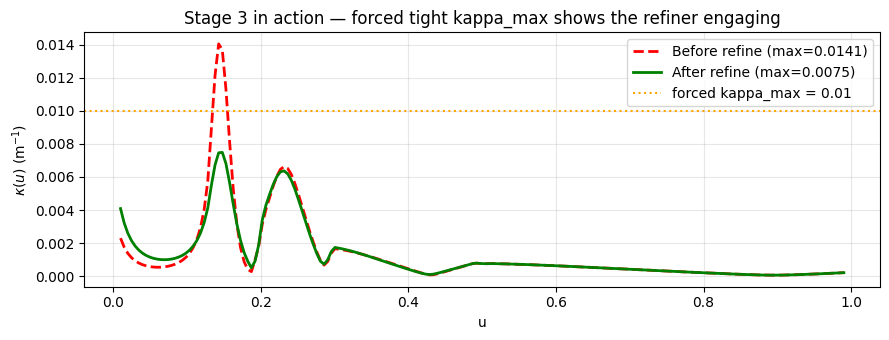

In [8]:
spline_forced = BSplinePath(waypoints, best_knots)
refiner = CurvatureRefiner(kappa_max=0.01, max_iters=30, step_size=10.0)

before = spline_forced.max_curvature()
refiner.refine(spline_forced, verbose=True)
after = spline_forced.max_curvature()

params = np.linspace(0.01, 0.99, 200)
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(params, [spline_ga.compute_curvature(u) for u in params], 'r--', lw=2, label=f'Before refine (max={before:.4f})')
ax.plot(params, [spline_forced.compute_curvature(u) for u in params], 'g-', lw=2, label=f'After refine (max={after:.4f})')
ax.axhline(0.01, color='orange', ls=':', label='forced kappa_max = 0.01')
ax.set_xlabel('u'); ax.set_ylabel(r'$\kappa(u)$ (m$^{-1}$)')
ax.set_title('Stage 3 in action — forced tight kappa_max shows the refiner engaging')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 1.8 The Full 3-Stage Pipeline — `AdaptiveBSplineSmoother`

`path_planning/path_smoother.py` chains Stage 1 (init) → Stage 2 (GA) → Stage 3 (refinement) behind one
call, exposing `stage1_spline` / `stage2_spline` / `stage3_spline` for comparison. This is what `main.py`
and the merged simulation in notebook 3 actually call.

In [9]:
smoother = AdaptiveBSplineSmoother(n_inner_knots=6, n_generations=30, population_size=20, kappa_max=0.5)
spline_adaptive = smoother.smooth(waypoints)

spline_uniform = BSplinePath(waypoints)
dist = np.linalg.norm(waypoints[-1] - waypoints[0])

rows = [
    ("Uniform B-Spline",        spline_uniform, spline_uniform.path_length()/dist),
    ("Adaptive B-Spline (GA+refine)", spline_adaptive, spline_adaptive.path_length()/dist),
]
print(f"\n{'Method':<32}{'Length(m)':>12}{'Max kappa':>12}{'Straightness':>14}")
for name, sp, sr in rows:
    print(f"{name:<32}{sp.path_length():>12.1f}{sp.max_curvature():>12.4f}{sr:>14.3f}")

[Stage 1] Baseline spline:      length=3065.4m, max_curvature=0.0070
Running Genetic Algorithm for knot optimization...
GA complete. Best cost: 2897.5973
[Stage 2] GA-optimized spline:   length=2897.6m, max_curvature=0.0979
  [refine] converged after 0 iterations (max curvature <= kappa_max=0.5)
[Stage 3] Curvature-refined spline: length=2897.6m, max_curvature=0.0979

Method                             Length(m)   Max kappa  Straightness
Uniform B-Spline                      3065.4      0.0070         1.137
Adaptive B-Spline (GA+refine)         2897.6      0.0979         1.074


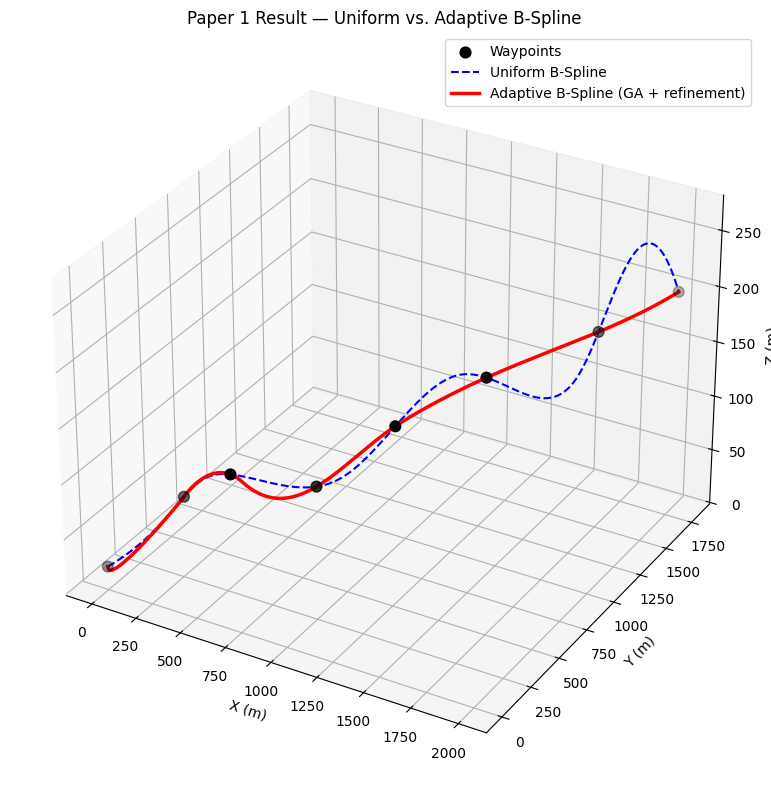

In [10]:
pts_u = spline_uniform.sample_path(300)
pts_a = spline_adaptive.sample_path(300)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(waypoints[:,0], waypoints[:,1], waypoints[:,2], c='black', s=60, label='Waypoints', zorder=5)
ax.plot(pts_u[:,0], pts_u[:,1], pts_u[:,2], 'b--', lw=1.5, label='Uniform B-Spline')
ax.plot(pts_a[:,0], pts_a[:,1], pts_a[:,2], 'r-', lw=2.5, label='Adaptive B-Spline (GA + refinement)')
ax.set_xlabel('X (m)'); ax.set_ylabel('Y (m)'); ax.set_zlabel('Z (m)')
ax.set_title('Paper 1 Result — Uniform vs. Adaptive B-Spline')
ax.legend()
plt.tight_layout()
plt.show()

## 1.9 Summary

- The 3D environment + A\* give a collision-free but jagged waypoint sequence.
- `BSplinePath` fits a $C^2$-continuous cubic B-Spline (Eq. 1) through those waypoints via chord-length
  parameterization + least-squares control points.
- `KnotGA` adaptively repositions interior knots (Stage 2) to minimize a 4-of-5-term version of the paper's
  objective (Eq. 4) — trading off data fidelity, curvature (Eq. 2), path length, and knot regularity.
- `CurvatureRefiner` (Stage 3, this project's own addition — was an empty placeholder before) performs the
  paper's local, derivative-free control-point search wherever curvature still exceeds $\kappa_{max}$.
- Known deviations from the paper (missing $F_{dyn}$ term, uniform vs. knot-averaging default, etc.) are
  documented in `implementation.md §5`.

**Next:** `02_quaternion_attitude_control_theory.ipynb` covers the attitude-control half (Paper 2).